In [1]:
!pip install -q pyspark gradio matplotlib pandas

In [2]:
from google.colab import files

uploaded = files.upload()

Saving Airline_Delay_Cause.csv to Airline_Delay_Cause.csv


In [4]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, sum as spark_sum, when
import pandas as pd
import matplotlib.pyplot as plt
import gradio as gr

spark = (
    SparkSession.builder
    .appName("Airline_Delay_Analysis.csv")
    .master("local[*]")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

file_name = list(uploaded.keys())[0]

df = spark.read.csv(
    file_name,
    header=True,
    inferSchema=True
)

# Standardize column names
for name in df.columns:
    df = df.withColumnRenamed(name, name.strip().lower())

print("Total rows:", df.count())
print("Columns:", df.columns)

df.show(5, truncate=False)
df.printSchema()

Total rows: 171666
Columns: ['year', 'month', 'carrier', 'carrier_name', 'airport', 'airport_name', 'arr_flights', 'arr_del15', 'carrier_ct', 'weather_ct', 'nas_ct', 'security_ct', 'late_aircraft_ct', 'arr_cancelled', 'arr_diverted', 'arr_delay', 'carrier_delay', 'weather_delay', 'nas_delay', 'security_delay', 'late_aircraft_delay']
+----+-----+-------+-----------------+-------+-----------------------------------------------------------+-----------+---------+----------+----------+------+-----------+----------------+-------------+------------+---------+-------------+-------------+---------+--------------+-------------------+
|year|month|carrier|carrier_name     |airport|airport_name                                               |arr_flights|arr_del15|carrier_ct|weather_ct|nas_ct|security_ct|late_aircraft_ct|arr_cancelled|arr_diverted|arr_delay|carrier_delay|weather_delay|nas_delay|security_delay|late_aircraft_delay|
+----+-----+-------+-----------------+-------+-------------------------

In [5]:
df = df.dropDuplicates()

df = df.dropna(
    subset=["year", "month", "carrier", "airport"]
)

numeric_columns = [
    "year", "month", "arr_flights",
    "arr_del15", "arr_cancelled", "arr_delay",
    "carrier_delay", "weather_delay",
    "nas_delay", "security_delay",
    "late_aircraft_delay"
]

for name in numeric_columns:
    if name in df.columns:
        df = df.withColumn(
            name, col(name).cast("double")
        )

count_columns = [
    "arr_flights", "arr_del15", "arr_cancelled",
    "arr_delay", "carrier_delay", "weather_delay",
    "nas_delay", "security_delay", "late_aircraft_delay"
]

df = df.fillna({
    name: 0 for name in count_columns
    if name in df.columns
})

df = df.filter(
    (col("month") >= 1) &
    (col("month") <= 12) &
    (col("arr_flights") >= 0) &
    (col("arr_del15") >= 0) &
    (col("arr_cancelled") >= 0)
)

if "carrier_name" in df.columns:
    df = df.withColumn("airline", col("carrier_name"))
else:
    df = df.withColumn("airline", col("carrier"))

if "airport_name" in df.columns:
    df = df.withColumn("airport_label", col("airport_name"))
else:
    df = df.withColumn("airport_label", col("airport"))

df = df.withColumn(
    "delay_rate",
    when(
        col("arr_flights") > 0,
        col("arr_del15") / col("arr_flights") * 100
    ).otherwise(0)
)

df = df.withColumn(
    "cancellation_rate",
    when(
        col("arr_flights") > 0,
        col("arr_cancelled") / col("arr_flights") * 100
    ).otherwise(0)
)

print("Rows after cleaning:", df.count())
df.show(5, truncate=False)

Rows after cleaning: 171666
+------+-----+-------+----------------------+-------+------------------------------------------------+-----------+---------+----------+----------+------+-----------+----------------+-------------+------------+---------+-------------+-------------+---------+--------------+-------------------+----------------------+------------------------------------------------+------------------+------------------+
|year  |month|carrier|carrier_name          |airport|airport_name                                    |arr_flights|arr_del15|carrier_ct|weather_ct|nas_ct|security_ct|late_aircraft_ct|arr_cancelled|arr_diverted|arr_delay|carrier_delay|weather_delay|nas_delay|security_delay|late_aircraft_delay|airline               |airport_label                                   |delay_rate        |cancellation_rate |
+------+-----+-------+----------------------+-------+------------------------------------------------+-----------+---------+----------+----------+------+-----------+-

In [6]:
summary = df.agg(
    spark_sum("arr_flights").alias("Total Flights"),
    spark_sum("arr_del15").alias("Delayed Flights"),
    spark_sum("arr_cancelled").alias("Cancelled Flights"),
    spark_sum("arr_delay").alias("Total Delay Minutes")
)

summary.show()

+-------------+---------------+-----------------+-------------------+
|Total Flights|Delayed Flights|Cancelled Flights|Total Delay Minutes|
+-------------+---------------+-----------------+-------------------+
|  6.2146805E7|    1.1375095E7|        1290923.0|       7.26758355E8|
+-------------+---------------+-----------------+-------------------+



In [7]:
airline_data = df.groupBy("airline").agg(
    spark_sum("arr_flights").alias("flights"),
    spark_sum("arr_del15").alias("delayed"),
    spark_sum("arr_cancelled").alias("cancelled")
)

airline_data = airline_data.withColumn(
    "delay_rate",
    when(
        col("flights") > 0,
        col("delayed") / col("flights") * 100
    ).otherwise(0)
)

airline_data.orderBy(
    col("delay_rate").desc()
).show(10, truncate=False)

+----------------------------+-----------+---------+---------+------------------+
|airline                     |flights    |delayed  |cancelled|delay_rate        |
+----------------------------+-----------+---------+---------+------------------+
|Frontier Airlines Inc.      |1158943.0  |291403.0 |22063.0  |25.143859534075446|
|JetBlue Airways             |2609697.0  |647919.0 |59509.0  |24.827365015938632|
|Allegiant Air               |613357.0   |149943.0 |24303.0  |24.44628495313496 |
|American Eagle Airlines Inc.|279283.0   |61132.0  |15074.0  |21.88890838325283 |
|Spirit Air Lines            |1526076.0  |330708.0 |34307.0  |21.67048036926077 |
|Virgin America              |301908.0   |64605.0  |3156.0   |21.398902977065863|
|ExpressJet Airlines Inc.    |2637669.0  |540578.0 |85844.0  |20.494535136895493|
|ExpressJet Airlines LLC     |149234.0   |29672.0  |8198.0   |19.882868515217712|
|Southwest Airlines Co.      |1.2522217E7|2460563.0|275976.0 |19.649579623160978|
|American Airlin

In [8]:
airport_data = df.groupBy("airport_label").agg(
    spark_sum("arr_flights").alias("flights"),
    spark_sum("arr_del15").alias("delayed"),
    spark_sum("arr_cancelled").alias("cancelled")
)

airport_data.orderBy(
    col("delayed").desc()
).show(10, truncate=False)

+------------------------------------------------------+---------+--------+---------+
|airport_label                                         |flights  |delayed |cancelled|
+------------------------------------------------------+---------+--------+---------+
|Chicago, IL: Chicago O'Hare International             |2774102.0|535940.0|80821.0  |
|Atlanta, GA: Hartsfield-Jackson Atlanta International |3557460.0|508434.0|45104.0  |
|Dallas/Fort Worth, TX: Dallas/Fort Worth International|2588687.0|481259.0|70542.0  |
|Denver, CO: Denver International                      |2391883.0|433104.0|46749.0  |
|Los Angeles, CA: Los Angeles International            |2017064.0|397496.0|28294.0  |
|San Francisco, CA: San Francisco International        |1501997.0|345825.0|29728.0  |
|Newark, NJ: Newark Liberty International              |1166485.0|288816.0|40826.0  |
|Phoenix, AZ: Phoenix Sky Harbor International         |1618391.0|274354.0|23389.0  |
|New York, NY: LaGuardia                              

In [9]:
monthly_data = df.groupBy("month").agg(
    spark_sum("arr_flights").alias("flights"),
    spark_sum("arr_del15").alias("delayed"),
    spark_sum("arr_cancelled").alias("cancelled")
)

monthly_data = monthly_data.withColumn(
    "delay_rate",
    when(
        col("flights") > 0,
        col("delayed") / col("flights") * 100
    ).otherwise(0)
).orderBy("month")

monthly_data.show(12)

+-----+---------+---------+---------+------------------+
|month|  flights|  delayed|cancelled|        delay_rate|
+-----+---------+---------+---------+------------------+
|  1.0|5037397.0| 918519.0| 151404.0| 18.23400061579423|
|  2.0|4653341.0| 855134.0| 135922.0| 18.37677488067176|
|  3.0|5457777.0| 928208.0| 196053.0|17.007070827554884|
|  4.0|4988672.0| 848691.0| 197530.0|17.012363210088775|
|  5.0|5050013.0| 907663.0|  70512.0|17.973478484114793|
|  6.0|5175726.0|1173371.0|  93292.0|22.670655285847822|
|  7.0|5490440.0|1204979.0|  89380.0| 21.94685671822295|
|  8.0|6034001.0|1209494.0| 102736.0| 20.04464367838189|
|  9.0|4969482.0| 703938.0|  65515.0|14.165218829648643|
| 10.0|5206266.0| 792054.0|  46886.0|15.213475454385158|
| 11.0|4985442.0| 751540.0|  39054.0| 15.07469147168897|
| 12.0|5098248.0|1081504.0| 102639.0|21.213248158975397|
+-----+---------+---------+---------+------------------+



In [10]:
delay_causes = [
    "carrier_delay",
    "weather_delay",
    "nas_delay",
    "security_delay",
    "late_aircraft_delay"
]

cause_values = df.agg(*[
    spark_sum(col(name)).alias(name)
    for name in delay_causes
]).first()

cause_data = pd.DataFrame({
    "Cause": delay_causes,
    "Delay Minutes": [
        cause_values[name] or 0
        for name in delay_causes
    ]
})

display(cause_data)

,Cause,Delay Minutes
0,carrier_delay,246370897.0
1,weather_delay,38153170.0
2,nas_delay,157823639.0
3,security_delay,1265591.0
4,late_aircraft_delay,283144335.0


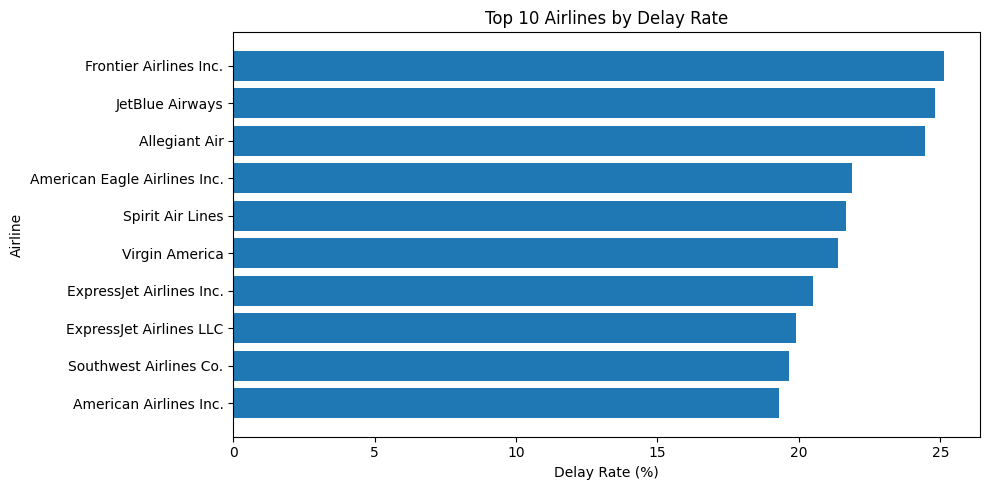

In [11]:
airline_pd = airline_data.orderBy(
    col("delay_rate").desc()
).limit(10).toPandas()

plt.figure(figsize=(10, 5))
plt.barh(airline_pd["airline"], airline_pd["delay_rate"])
plt.title("Top 10 Airlines by Delay Rate")
plt.xlabel("Delay Rate (%)")
plt.ylabel("Airline")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

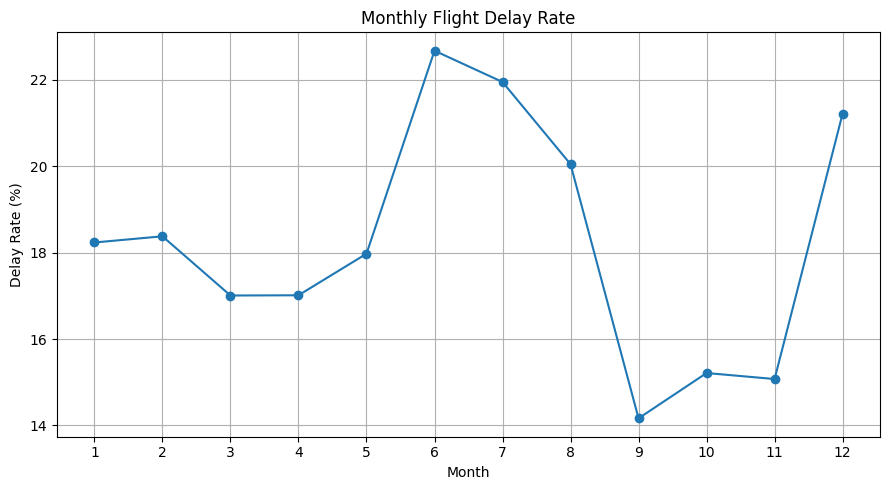

In [12]:
monthly_pd = monthly_data.toPandas()

plt.figure(figsize=(9, 5))
plt.plot(
    monthly_pd["month"],
    monthly_pd["delay_rate"],
    marker="o"
)
plt.title("Monthly Flight Delay Rate")
plt.xlabel("Month")
plt.ylabel("Delay Rate (%)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

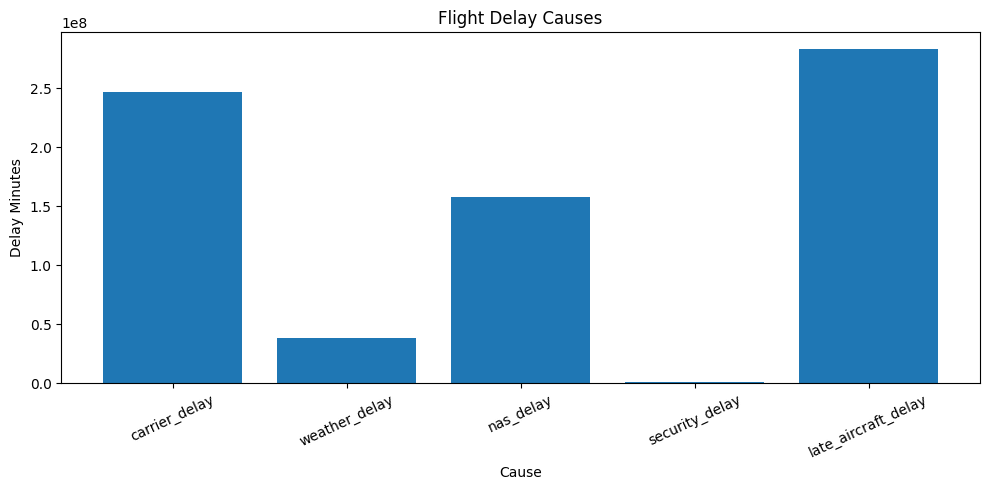

In [13]:
plt.figure(figsize=(10, 5))
plt.bar(cause_data["Cause"], cause_data["Delay Minutes"])
plt.title("Flight Delay Causes")
plt.xlabel("Cause")
plt.ylabel("Delay Minutes")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [19]:
def analyze(airline, airport, month):
    try:
        data = df

        if airline != "All Airlines":
            data = data.filter(col("airline") == airline)

        if airport != "All Airports":
            data = data.filter(col("airport_label") == airport)

        if month != "All Months":
            data = data.filter(col("month").cast("int") == int(month))

        if data.limit(1).count() == 0:
            return (
                "No matching data found. Please change your filters.",
                None, None, None, pd.DataFrame()
            )

        summary = get_summary(data)

        airline_data = data.groupBy("airline").agg(
            spark_sum("arr_flights").alias("flights"),
            spark_sum("arr_del15").alias("delayed")
        ).toPandas()

        airline_data["delay_rate"] = (
            airline_data["delayed"] /
            airline_data["flights"].replace(0, float("nan")) * 100
        )
        airline_data = airline_data.dropna(subset=["delay_rate"])

        fig1, ax1 = plt.subplots(figsize=(8, 4))
        ax1.bar(airline_data["airline"], airline_data["delay_rate"])
        ax1.set_title("Airline Delay Rate")
        ax1.set_ylabel("Delay Rate (%)")
        ax1.tick_params(axis="x", rotation=45)
        fig1.tight_layout()

        airport_data = data.groupBy("airport_label").agg(
            spark_sum("arr_del15").alias("delayed")
        ).toPandas()

        airport_data = airport_data.dropna(subset=["airport_label"])

        fig2, ax2 = plt.subplots(figsize=(8, 4))
        ax2.bar(airport_data["airport_label"], airport_data["delayed"])
        ax2.set_title("Airport Delayed Flights")
        ax2.set_ylabel("Delayed Flights")
        ax2.tick_params(axis="x", rotation=45)
        fig2.tight_layout()

        month_data = data.groupBy("month").agg(
            spark_sum("arr_flights").alias("flights"),
            spark_sum("arr_del15").alias("delayed")
        ).orderBy("month").toPandas()

        month_data["delay_rate"] = (
            month_data["delayed"] /
            month_data["flights"].replace(0, float("nan")) * 100
        )

        fig3, ax3 = plt.subplots(figsize=(8, 4))
        ax3.plot(
            month_data["month"],
            month_data["delay_rate"],
            marker="o"
        )
        ax3.set_title("Monthly Delay Rate")
        ax3.set_xlabel("Month")
        ax3.set_ylabel("Delay Rate (%)")
        fig3.tight_layout()

        table = data.select(
            "year", "month", "airline", "airport_label",
            "arr_flights", "arr_del15", "arr_cancelled"
        ).limit(100).toPandas()

        return summary, fig1, fig2, fig3, table

    except Exception as e:
        return (
            f"Error: {str(e)}",
            None, None, None, pd.DataFrame()
        )

In [24]:
import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql.functions import col, sum as spark_sum, avg, when

# Get dropdown options from actual data
airlines = sorted([
    r["airline"] for r in
    df.select("airline").distinct().collect()
    if r["airline"] is not None
])

airports = sorted([
    r["airport_label"] for r in
    df.select("airport_label").distinct().collect()
    if r["airport_label"] is not None
])

def make_chart():
    fig, ax = plt.subplots(figsize=(7, 3))
    return fig, ax

def analyze_dashboard(airline, airport, month):
    data = df

    if airline != "All Airlines":
        data = data.filter(col("airline") == airline)

    if airport != "All Airports":
        data = data.filter(col("airport_label") == airport)

    if month != "All Months":
        data = data.filter(col("month").cast("int") == int(month))

    if data.limit(1).count() == 0:
        fig1, ax1 = make_chart()
        ax1.text(0.5, 0.5, "No matching records",
                 ha="center", va="center")
        ax1.axis("off")

        fig2, ax2 = make_chart()
        ax2.text(0.5, 0.5, "No matching records",
                 ha="center", va="center")
        ax2.axis("off")

        fig3, ax3 = make_chart()
        ax3.text(0.5, 0.5, "No matching records",
                 ha="center", va="center")
        ax3.axis("off")

        fig4, ax4 = make_chart()
        ax4.text(0.5, 0.5, "No matching records",
                 ha="center", va="center")
        ax4.axis("off")

        return (
            "No matching data. Please change the filters.",
            "0", "0", "0", "N/A",
            fig1, fig2, fig3, fig4, pd.DataFrame()
        )

    # KPI calculations
    totals = data.agg(
        spark_sum("arr_flights").alias("flights"),
        spark_sum("arr_del15").alias("delayed"),
        spark_sum("arr_cancelled").alias("cancelled"),
        spark_sum("arr_delay").alias("delay")
    ).first()

    flights = totals["flights"] or 0
    delayed = totals["delayed"] or 0
    cancelled = totals["cancelled"] or 0
    delay_minutes = totals["delay"] or 0

    avg_delay = delay_minutes / flights if flights else 0
    on_time = max(flights - delayed, 0)
    on_time_rate = on_time / flights * 100 if flights else 0
    delayed_rate = delayed / flights * 100 if flights else 0

    summary = f"""
### ✈️ Flight Operations Dashboard
**Filters:** Airline: {airline} | Airport: {airport} | Month: {month}
"""

    # Airline performance chart
    airline_data = data.groupBy("airline").agg(
        spark_sum("arr_flights").alias("flights"),
        spark_sum("arr_del15").alias("delayed")
    ).toPandas()

    airline_data["on_time_pct"] = (
        (airline_data["flights"] - airline_data["delayed"]).clip(lower=0)
        / airline_data["flights"].replace(0, float("nan")) * 100
    )
    airline_data["delayed_pct"] = (
        airline_data["delayed"]
        / airline_data["flights"].replace(0, float("nan")) * 100
    )
    airline_data = airline_data.dropna().sort_values(
        "flights", ascending=False
    ).head(10)

    fig1, ax1 = make_chart()
    if not airline_data.empty:
        x = range(len(airline_data))
        ax1.bar(x, airline_data["on_time_pct"], label="On-time %")
        ax1.bar(
            x, airline_data["delayed_pct"],
            bottom=airline_data["on_time_pct"],
            label="Delayed %"
        )
        ax1.set_xticks(list(x))
        ax1.set_xticklabels(airline_data["airline"], rotation=35, ha="right")
        ax1.legend()
    ax1.set_title("Airline Performance")
    ax1.set_ylabel("Percentage")
    ax1.set_ylim(0, 100)
    fig1.tight_layout()

    # Monthly delay trend: average delay minutes per arriving flight
    monthly = data.groupBy("month").agg(
        spark_sum("arr_delay").alias("delay"),
        spark_sum("arr_flights").alias("flights")
    ).orderBy("month").toPandas()

    monthly["avg_delay"] = (
        monthly["delay"] / monthly["flights"].replace(0, float("nan"))
    )

    fig2, ax2 = make_chart()
    if not monthly.empty:
        ax2.plot(monthly["month"], monthly["avg_delay"], marker="o")
    ax2.set_title("Monthly Average Arrival Delay")
    ax2.set_xlabel("Month")
    ax2.set_ylabel("Minutes per flight")
    ax2.set_xticks(range(1, 13))
    ax2.grid(True, alpha=0.3)
    fig2.tight_layout()

    # Cancellation analysis by airline
    cancellations = data.groupBy("airline").agg(
        spark_sum("arr_cancelled").alias("cancelled")
    ).filter(col("cancelled") > 0).toPandas()

    cancellations = cancellations.sort_values(
        "cancelled", ascending=False
    ).head(8)

    fig3, ax3 = make_chart()
    if not cancellations.empty:
        ax3.pie(
            cancellations["cancelled"],
            labels=cancellations["airline"],
            autopct="%1.1f%%",
            startangle=90
        )
    else:
        ax3.text(0.5, 0.5, "No cancellations found",
                 ha="center", va="center")
    ax3.set_title("Cancellation Distribution by Airline")
    fig3.tight_layout()

    # Airport comparison chart
    airport_data = data.groupBy("airport_label").agg(
        spark_sum("arr_delay").alias("delay"),
        spark_sum("arr_flights").alias("flights")
    ).toPandas()

    airport_data["avg_delay"] = (
        airport_data["delay"] /
        airport_data["flights"].replace(0, float("nan"))
    )
    airport_data = airport_data.dropna().sort_values(
        "avg_delay", ascending=False
    ).head(10)

    fig4, ax4 = make_chart()
    if not airport_data.empty:
        ax4.barh(airport_data["airport_label"], airport_data["avg_delay"])
        ax4.invert_yaxis()
    ax4.set_title("Airport Comparison")
    ax4.set_xlabel("Average Arrival Delay (minutes)")
    fig4.tight_layout()

    # Data table
    table = data.select(
        "year", "month", "airline", "airport_label",
        "arr_flights", "arr_del15", "arr_cancelled", "arr_delay"
    ).limit(100).toPandas()

    return (
        summary,
        f"{flights:,.0f}",
        f"{delayed:,.0f}",
        f"{cancelled:,.0f}",
        f"{avg_delay:.1f} min",
        fig1, fig2, fig3, fig4, table
    )


with gr.Blocks(
    theme=gr.themes.Soft(),
    title="Flight Operations Dashboard"
) as demo:

    gr.Markdown("""
    # ✈️ Flight Operations Dashboard
    **Big Data Analytics using Apache Spark and PySpark**
    """)

    with gr.Row():
        airline_filter = gr.Dropdown(
            ["All Airlines"] + airlines,
            value="All Airlines",
            label="Select Airline"
        )
        airport_filter = gr.Dropdown(
            ["All Airports"] + airports,
            value="All Airports",
            label="Select Airport"
        )
        month_filter = gr.Dropdown(
            ["All Months"] + [str(i) for i in range(1, 13)],
            value="All Months",
            label="Select Month"
        )

    run_button = gr.Button("Analyze Flights", variant="primary")
    summary = gr.Markdown()

    with gr.Row():
        kpi1 = gr.Textbox(label="TOTAL FLIGHTS", interactive=False)
        kpi2 = gr.Textbox(label="DELAYED FLIGHTS", interactive=False)
        kpi3 = gr.Textbox(label="CANCELLED FLIGHTS", interactive=False)
        kpi4 = gr.Textbox(label="AVG. ARRIVAL DELAY", interactive=False)

    with gr.Row():
        with gr.Column():
            gr.Markdown("### Airline Performance")
            chart1 = gr.Plot()
        with gr.Column():
            gr.Markdown("### Monthly Delay Trends")
            chart2 = gr.Plot()

    with gr.Row():
        with gr.Column():
            gr.Markdown("### Cancellation Analysis")
            chart3 = gr.Plot()
        with gr.Column():
            gr.Markdown("### Airport Comparison")
            chart4 = gr.Plot()

    gr.Markdown("### Filtered Flight Records")
    table_output = gr.Dataframe()

    outputs = [
        summary, kpi1, kpi2, kpi3, kpi4,
        chart1, chart2, chart3, chart4, table_output
    ]

    run_button.click(
        analyze_dashboard,
        inputs=[airline_filter, airport_filter, month_filter],
        outputs=outputs
    )

    demo.load(
        analyze_dashboard,
        inputs=[airline_filter, airport_filter, month_filter],
        outputs=outputs
    )

demo.launch(share=True)

/tmp/ipykernel_684/4142869501.py:201: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://493633a7dd4e868c1c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
